In [1]:
import gc                                # garbage collector, used to free RAM
import numpy as np                       # NumPy: numerical arrays
import pandas as pd                      # pandas: tables
import scanpy as sc                      # Scanpy: single-cell analysis
import matplotlib.pyplot as plt          # matplotlib: plotting
from pathlib import Path                 # Path: file and folder paths

project_dir = Path.cwd().parent          # notebook lives in Notebook/, so parent = project root
proc_dir = project_dir / "data" / "processed"
fig_dir  = project_dir / "Figure"
fig_dir.mkdir(parents=True, exist_ok=True)

adata = sc.read_h5ad(proc_dir / "merged_normalized.h5ad")   # log-normalised data with raw counts in layers["counts"]
print(adata)

AnnData object with n_obs × n_vars = 13240 × 36601
    obs: 'total_counts', 'timepoint', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'sample', 'doublet_score', 'scrublet_called', 'high_doublet_score'
    var: 'gene_id', 'mt', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'hvg', 'log1p'
    layers: 'counts'


C:\Users\ADMIN\miniconda3\envs\blastoid\Lib\functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


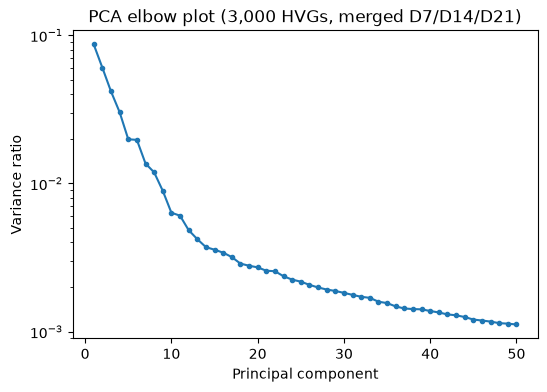

In [2]:
# Work on a copy that contains only the 3,000 highly variable genes
hv = adata[:, adata.var["highly_variable"]].copy()

# Scale each gene to mean 0 and variance 1, so highly expressed genes do not dominate the PCA.
# max_value=10 clips extreme values (more than 10 standard deviations) to limit the influence of outliers.
sc.pp.scale(hv, max_value=10)

# PCA: summarise the 3,000 genes into 50 principal components.
# svd_solver="arpack" is a fast, deterministic solver; random_state=0 makes results reproducible.
sc.tl.pca(hv, n_comps=50, svd_solver="arpack", random_state=0)

# Elbow plot: fraction of variance explained by each component (log y-axis).
# The "elbow" is where the curve flattens: components after it mostly capture noise.
var_ratio = hv.uns["pca"]["variance_ratio"]
plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, 51), var_ratio, "o-", markersize=3)
plt.yscale("log")
plt.xlabel("Principal component")
plt.ylabel("Variance ratio")
plt.title("PCA elbow plot (3,000 HVGs, merged D7/D14/D21)")
plt.savefig(fig_dir / "pca_variance_ratio.png", dpi=200, bbox_inches="tight")
plt.show()

In [3]:
N_PCS = 20                                   # use the first 20 principal components (chosen from the elbow plot)

# Neighbors graph: connect each cell to its 15 most similar cells in PCA space.
# This graph is the basis of both the UMAP layout and the clustering done in the next notebook.
sc.pp.neighbors(hv, n_neighbors=15, n_pcs=N_PCS, random_state=0)

# UMAP: a 2-D map in which cells with similar profiles lie close together.
sc.tl.umap(hv, random_state=0)

C:\Users\ADMIN\miniconda3\envs\blastoid\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


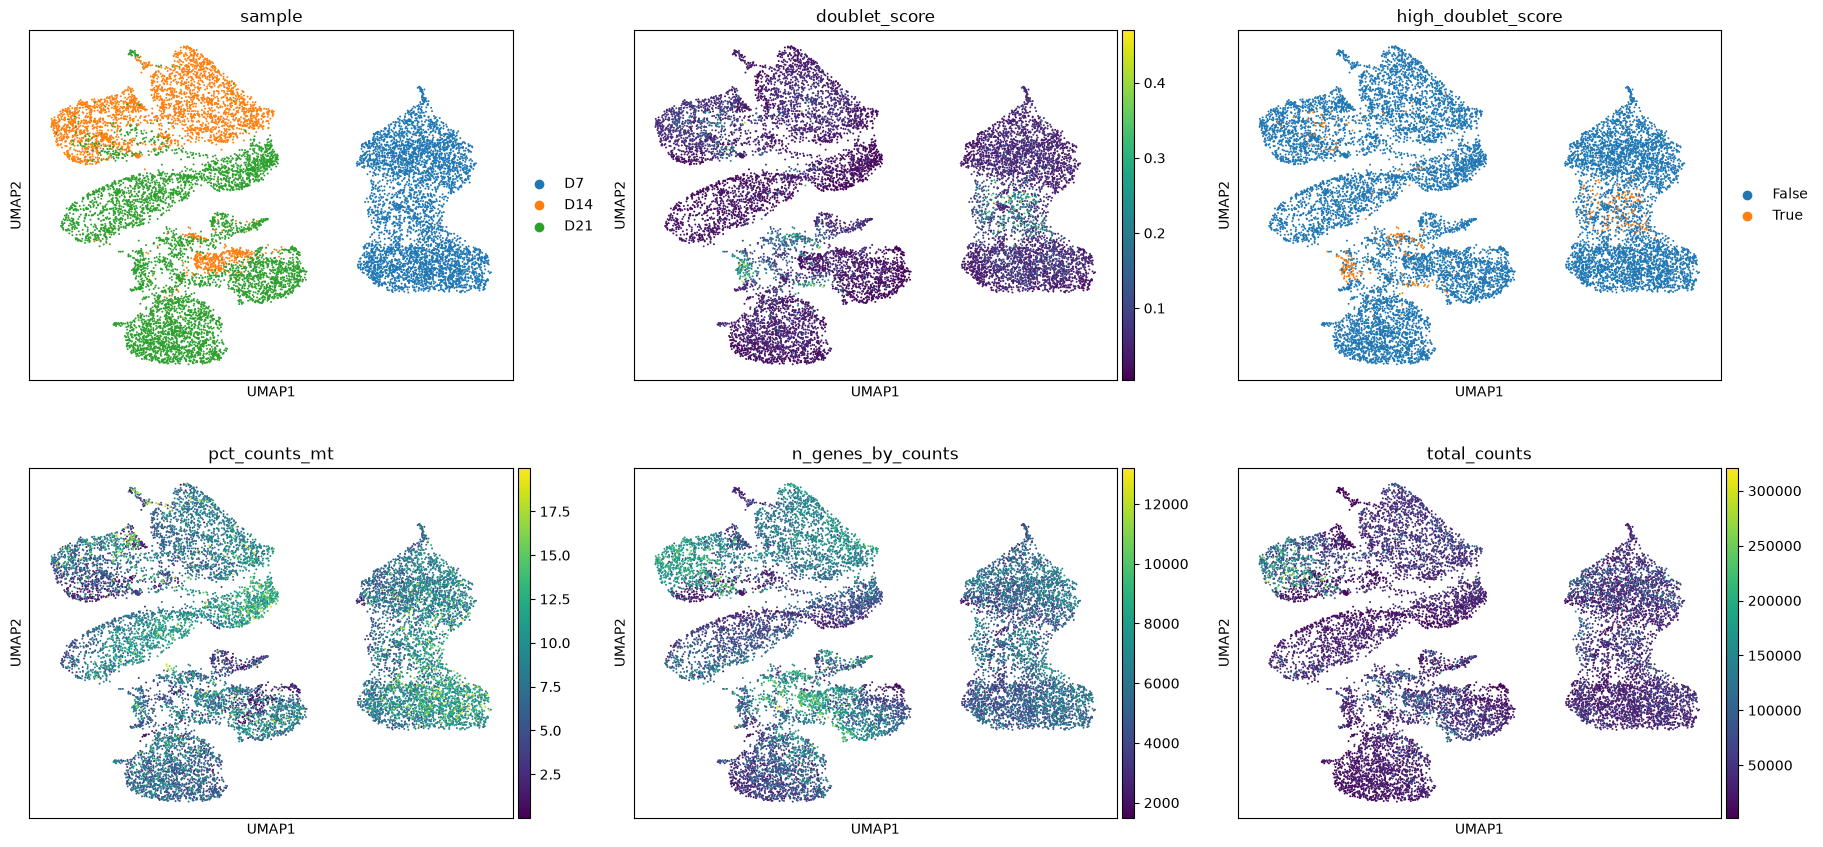

In [4]:
# Six panels: sample, two doublet-related colourings, and three QC metrics
colors = ["sample", "doublet_score", "high_doublet_score", "pct_counts_mt", "n_genes_by_counts", "total_counts"]
sc.pl.umap(hv, color=colors, ncols=3, size=8, show=False)   # size = dot size; show=False so we can save the figure first
plt.gcf().savefig(fig_dir / "umap_unintegrated_qc.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
# Copy the embeddings and the neighbors graph back to the full object (all 36,601 genes)
adata.obsm["X_pca"]  = hv.obsm["X_pca"]
adata.obsm["X_umap"] = hv.obsm["X_umap"]
adata.obsp["connectivities"] = hv.obsp["connectivities"]
adata.obsp["distances"]      = hv.obsp["distances"]
adata.uns["neighbors"] = hv.uns["neighbors"]
adata.uns["pca"]  = hv.uns["pca"]
adata.uns["umap"] = hv.uns["umap"]

adata.write_h5ad(proc_dir / "merged_umap.h5ad", compression="gzip")
print("Saved:", (proc_dir / "merged_umap.h5ad").stat().st_size / 1024**2, "MB")
del hv
gc.collect()

Saved: 308.64768505096436 MB


56387